In [1]:
# https://www.kaggle.com/datasets/ashfakyeafi/spam-email-classification

import kagglehub

# Download latest version
path = kagglehub.dataset_download("ashfakyeafi/spam-email-classification")

print("Path to dataset files:", path)

Path to dataset files: /home/rpsingh/.cache/kagglehub/datasets/ashfakyeafi/spam-email-classification/versions/3


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from datetime import datetime
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer


In [3]:
plt.style.use('ggplot')

In [4]:
df = pd.read_csv('/home/rpsingh/.cache/kagglehub/datasets/ashfakyeafi/spam-email-classification/versions/3/email.csv')

In [5]:
df.tail(2)

,Category,Message
5571,ham,Rofl. Its true to its name
5572,"{""mode"":""full""",isActive:false}


In [6]:
df = df.iloc[:-1]

In [7]:
df['Category'].unique()

<ArrowStringArray>
['ham', 'spam']
Length: 2, dtype: str

In [8]:
df.isna().sum().sum()

np.int64(0)

In [9]:
df.duplicated().sum()/df.shape[0]

np.float64(0.07447954055994258)

In [10]:
df.drop_duplicates(inplace=True)
df.duplicated().sum()

np.int64(0)

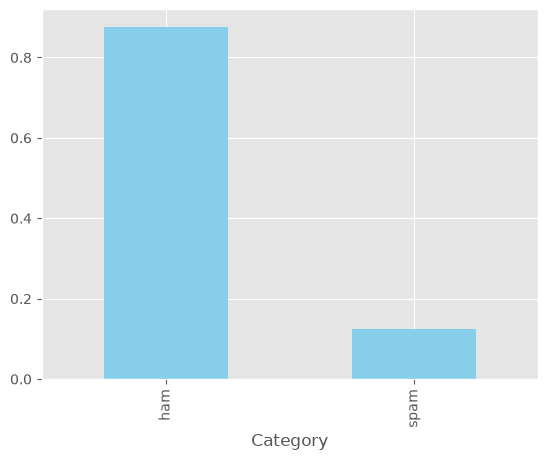

In [11]:
df['Category'].value_counts(normalize=True).plot(kind='bar', color='skyblue')
plt.show()

In [12]:
df['Message_len'] = df['Message'].apply(len)

In [13]:
df['Message_len'].describe()

count    5157.000000
mean       79.103936
std        58.382922
min         2.000000
25%        36.000000
50%        61.000000
75%       118.000000
max       910.000000
Name: Message_len, dtype: float64

Text(0.5, 1.0, 'Distibustion message leanght')

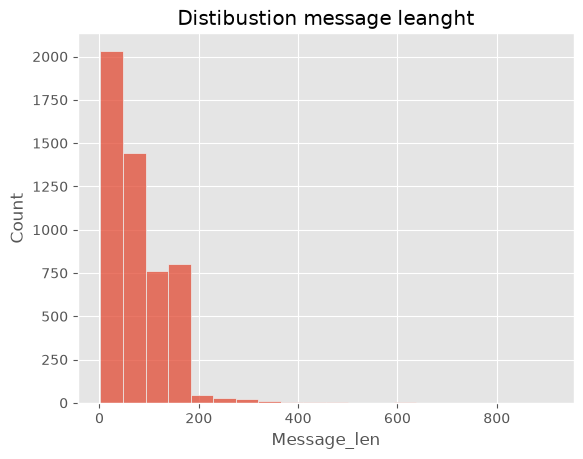

In [14]:
sns.histplot(data=df['Message_len'], bins=20)
plt.title('Distibustion message leanght')

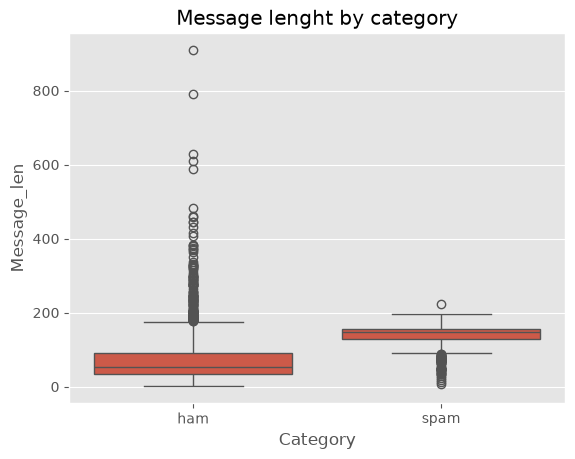

In [15]:
sns.boxplot(data=df, x='Category', y='Message_len')
plt.title("Message lenght by category")
plt.show()

In [16]:
df['Word_count'] = df['Message'].apply(lambda x: len(x.split()))

In [17]:
df.head(2)

,Category,Message,Message_len,Word_count
0,ham,"Go until jurong point, crazy.. Available only ...",111,20
1,ham,Ok lar... Joking wif u oni...,29,6


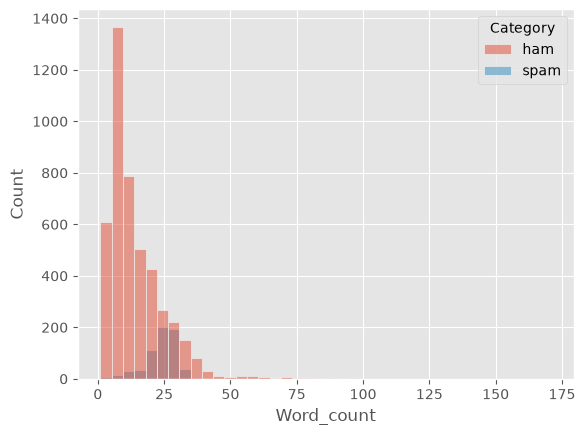

In [18]:
sns.histplot(data=df, x='Word_count', hue='Category', bins=40)
plt.show()

In [19]:
df.nsmallest(10, 'Message_len')

,Category,Message,Message_len,Word_count
1925,ham,Ok,2,1
3376,ham,:),2,1
261,ham,Yup,3,1
1612,ham,645,3,1
2182,ham,Ok.,3,1
287,ham,Ok..,4,1
2602,ham,Okie,4,1
5173,ham,U 2.,4,2
1273,ham,Ok...,5,1
4293,ham,G.W.R,5,1


In [20]:
df['Category'] = df['Category'].map({
    'ham': 0,
    'spam': 1,
})
df.head()

,Category,Message,Message_len,Word_count
0,0,"Go until jurong point, crazy.. Available only ...",111,20
1,0,Ok lar... Joking wif u oni...,29,6
2,1,Free entry in 2 a wkly comp to win FA Cup fina...,155,28
3,0,U dun say so early hor... U c already then say...,49,11
4,0,"Nah I don't think he goes to usf, he lives aro...",61,13


In [21]:
X = df['Message']
y = df['Category']

In [22]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

In [23]:
tfidf = TfidfVectorizer(stop_words='english', max_features=5000, ngram_range=(1,2))

In [24]:
X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

In [25]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

from sklearn.metrics import classification_report, f1_score, accuracy_score, roc_auc_score, precision_score, recall_score, precision_recall_curve
from sklearn.model_selection import RandomizedSearchCV

In [26]:
import warnings
warnings.filterwarnings("ignore")

In [27]:
model_list = {
    "NavinsBayes": (
        MultinomialNB(),
        {
            'alpha': [0.1, 0.2, 0.5, 1, 2, 5]
        }
    ),
    "LogisticRegression": (
        LogisticRegression(
            class_weight='balanced',
            max_iter=1000,
        ),
        {
            'C': [0.01, 0.05, 0.1, 1, 10, 100, 110, 120]
        }
    ),
    "LinearSVC": (
        LinearSVC(
            class_weight='balanced',
        ),
        {
            'C': [.01, .05, 0.1, 1, 10, 100]
        }
    ),
    "RandomForestClassifier": (
        RandomForestClassifier(
            class_weight='balanced',
            n_jobs=1,
        ),
        {
            'n_estimators': [100, 200, 300, 400, 450, 500],
            'max_depth': [3, 5, 6, 7, 8, 9, 10, None],
            'min_samples_split': [2, 5, 10, 50, 100]
        }
    ),
    "DecisionTreeClassifier" : (
        DecisionTreeClassifier(
            class_weight='balanced'
        ),
        {
            'max_depth': [3, 5, 6, 7, 8, 9, 10, None],
            'min_samples_split': [2, 5, 10, 50, 100]
        }
    ),
    # "GradientBoostingClassifier": (
    #     GradientBoostingClassifier(),
    #     {
    #         'n_estimators': [100, 200, 300, 400],
    #         'max_depth': [3, 5, 7, 8, 9, 10, None],
    #         'learning_rate': [0.01, 0.02, 0.04, 0.045, 0.05, 0.1],
    #         'min_samples_split': [2, 5, 10, 50, 100],
    #     }
    # ),
    "KNeighborsClassifier": (
        KNeighborsClassifier(),
        {
            'n_neighbors': [3, 5, 7, 9, 12]
        }
    ),
    "XGBClassifier": (
        XGBClassifier(n_jobs=1,),
        {
            'n_estimators': [100, 200, 300, 400, 500, 600, 700, 800, 900, 1000],
            'learning_rate': [0.01, 0.02, 0.04, 0.045, 0.05, 0.1],
            'max_depth': [3, 5, 7, 8, 9, 10, None],
            'min_child_weight': [1, 2, 5, 7, 10],
            'subsample': [0.1, 0.2, 0.3, 0.5, 0.7, 1],
            'colsample_bytree': [0.1, 0.2, 0.3, 0.5, 0.7, 1],
        }
    ),
    "LightGBM": (
        LGBMClassifier(verbosity=-1, n_jobs=1),
        {
            'n_estimators': [100, 200, 300, 400, 500, 600, 700, 800, 900, 1000, 1050, 1100, 1150, 1200, 1250, 1300, 1350, 1400, 1450, 1500],
            'learning_rate': [0.01, 0.02, 0.04, 0.045, 0.05, 0.1],
            'max_depth': [3, 5, 7, 8, 9, 10, None],
            'min_child_weight': [1, 2, 5, 7, 10],
            'subsample': [0.1, 0.2, 0.3, 0.5, 0.7, 1],
            'colsample_bytree': [0.1, 0.2, 0.3, 0.5, 0.7, 1],
        }
    )
}

In [28]:
results, best_models = [], {}

for name, (model, params) in model_list.items():
    start_time = datetime.now()

    search = RandomizedSearchCV(
        estimator=model,
        param_distributions=params,
        n_iter=25,
        cv=5,
        scoring="f1",
        n_jobs=-1,
        random_state=42
    )
    print(f"{name[:24]:<25}:", end=' ')

    search.fit(X_train_tfidf, y_train)
    best_model = search.best_estimator_
    best_models[name] = best_model

    pred = best_model.predict(X_test_tfidf)
    ac_score = accuracy_score(y_test, pred)
    pr_score = precision_score(y_test, pred)
    rc_score = recall_score(y_test, pred)
    fo_score = f1_score(y_test, pred)

    try:
        auc = roc_auc_score(y_test, best_model.decision_function(X_test_tfidf))
    except:
        try:
            auc = roc_auc_score(y_test, best_model.predict_proba(X_test_tfidf)[:, 1])
        except Exception as ex:
            print(ex)
            auc = np.nan
    results.append({
        "name": name,
        "accuracy_score": ac_score,
        "precision_score": pr_score,
        "recall_score": rc_score,
        "f1_score": fo_score,
        "roc_auc_score": auc,
        "best_params": search.best_params_,
    })
    end_time = datetime.now()
    time_diff_seconds = (end_time - start_time).total_seconds()
    print(f"Total Time in seconds: {time_diff_seconds:.2f}, f1 Score: {fo_score:.4f}, roc_auc_score: {auc:.4f}")

NavinsBayes              : Total Time in seconds: 3.20, f1 Score: 0.9212, roc_auc_score: 0.9900
LogisticRegression       : Total Time in seconds: 0.40, f1 Score: 0.9012, roc_auc_score: 0.9913
LinearSVC                : Total Time in seconds: 0.36, f1 Score: 0.9113, roc_auc_score: 0.9911
RandomForestClassifier   : Total Time in seconds: 25.70, f1 Score: 0.8830, roc_auc_score: 0.9901
DecisionTreeClassifier   : Total Time in seconds: 0.99, f1 Score: 0.7836, roc_auc_score: 0.9045
KNeighborsClassifier     : Total Time in seconds: 0.48, f1 Score: 0.6087, roc_auc_score: 0.7932
XGBClassifier            : Total Time in seconds: 34.90, f1 Score: 0.8571, roc_auc_score: 0.9806
LightGBM                 : Total Time in seconds: 8.31, f1 Score: 0.8692, roc_auc_score: 0.9754


In [29]:
results_df = pd.DataFrame(results)
results_df = results_df.sort_values(
    by=['f1_score', 'roc_auc_score'],
    ascending=False
)

In [30]:

results_df.style.background_gradient(
    cmap='Greens',
    subset=['accuracy_score', 'precision_score', 'recall_score', 'f1_score', 'roc_auc_score']
)

,name,accuracy_score,precision_score,recall_score,f1_score,roc_auc_score,best_params
0,NavinsBayes,0.981589,0.982301,0.867188,0.921162,0.989954,{'alpha': 0.1}
2,LinearSVC,0.978682,0.941667,0.882812,0.911290,0.991055,{'C': 1}
1,LogisticRegression,0.975775,0.912000,0.890625,0.901186,0.991345,{'C': 10}
3,RandomForestClassifier,0.969961,0.854015,0.914062,0.883019,0.990113,"{'n_estimators': 500, 'min_samples_split': 50, 'max_depth': None}"
7,LightGBM,0.969961,0.944954,0.804688,0.869198,0.975435,"{'subsample': 0.5, 'n_estimators': 1400, 'min_child_weight': 1, 'max_depth': 7, 'learning_rate': 0.04, 'colsample_bytree': 0.5}"
6,XGBClassifier,0.968023,0.961165,0.773438,0.857143,0.980581,"{'subsample': 1, 'n_estimators': 600, 'min_child_weight': 1, 'max_depth': 8, 'learning_rate': 0.05, 'colsample_bytree': 0.7}"
4,DecisionTreeClassifier,0.943798,0.750000,0.820312,0.783582,0.904470,"{'min_samples_split': 10, 'max_depth': None}"
5,KNeighborsClassifier,0.930233,1.000000,0.437500,0.608696,0.793211,{'n_neighbors': 3}


In [31]:
best_model_name = results_df.iloc[0]["name"]
print(f"best model: {best_model_name}")
best_model = best_models[best_model_name]

best model: NavinsBayes


In [32]:
best_model

,"alpha alpha: float or array-like of shape (n_features,), default=1.0Additive (Laplace/Lidstone) smoothing parameter(set alpha=0 and force_alpha=True, for no smoothing).",0.1
,"force_alpha force_alpha: bool, default=TrueIf False and alpha is less than 1e-10, it will set alpha to1e-10. If True, alpha will remain unchanged. This may causenumerical errors if alpha is too close to 0... versionadded:: 1.2.. versionchanged:: 1.4 The default value of `force_alpha` changed to `True`.",True
,"fit_prior fit_prior: bool, default=TrueWhether to learn class prior probabilities or not.If false, a uniform prior will be used.",True
,"class_prior class_prior: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
Name,Type,Value
"class_count_ class_count_: ndarray of shape (n_classes,)Number of samples encountered for each class during fitting. Thisvalue is weighted by the sample weight when provided.","ndarray[float64](2,)","[3612., 513.]"
"class_log_prior_ class_log_prior_: ndarray of shape (n_classes,)Smoothed empirical log probability for each class.","ndarray[float64](2,)","[-0.13,-2.08]"
"classes_ classes_: ndarray of shape (n_classes,)Class labels known to the classifier","ndarray[int64](2,)","[0,1]"
"feature_count_ feature_count_: ndarray of shape (n_classes, n_features)Number of samples encountered for each (class, feature)during fitting. This value is weighted by the sample weight whenprovided.","ndarray[float64](2, 5000)","[[0. ,0. ,0. ,...,0.82,1.39,0. ], [0.97,0.38,4.05,...,0. ,0. ,0.69]]"
"feature_log_prob_ feature_log_prob_: ndarray of shape (n_classes, n_features)Empirical log probability of featuresgiven a class, ``P(x_i|y)``.","ndarray[float64](2, 5000)","[[-11.4 ,-11.4 ,-11.4 ,..., -9.17, -8.69,-11.4 ], [ -7.8 , -8.61, -6.44,...,-10.17,-10.17, -8.1 ]]"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,5000


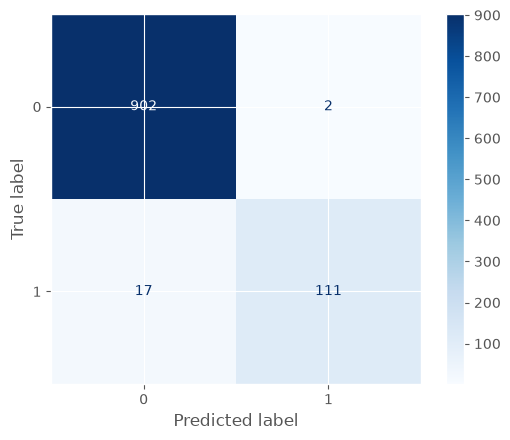

In [33]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_estimator(
    best_model,
    X_test_tfidf,
    y_test,
    cmap="Blues"
)
plt.show()

# Check for custom input

In [34]:
emails = [
    "Congratulations! You have been selected for a $1,000,000 cash prize. Claim now!",
    "URGENT: Your account has been compromised. Verify your information immediately.",
    "You have won an exclusive prize! Click here to claim your reward.",
    "Act now! Limited-time offer — get 90% off today only.",
    "Your payment has failed. Update your billing information immediately.",
    "Congratulations! You are our lucky winner. Send your details to receive your prize.",
    "FINAL NOTICE: Your subscription will be cancelled unless you confirm your account.",
    "Earn $5,000 per week working from home. No experience required!",
    "You have been pre-approved for a special cash loan. Apply now.",
    "Exclusive offer just for you! Buy now and receive a free gift.",
    "Your package is waiting. Pay the delivery fee to schedule delivery.",
    "Security Alert: Confirm your identity to prevent account suspension.",
    "Claim your free gift card before this offer expires.",
    "You have inherited money from an unknown relative. Contact us immediately.",
    "Double your money fast with this secret investment opportunity.",

    "Your order has been shipped and is expected to arrive on Friday.",
    "Hi Sarah, just checking if we're still meeting at 3 PM tomorrow.",
    "Please find attached the monthly sales report for your review.",
    "Reminder: Your dentist appointment is scheduled for Monday at 10 AM.",
    "Thanks for your purchase. Your receipt is attached to this email.",
    "The team meeting has been moved to 2:30 PM due to a scheduling conflict.",
    "Your password was successfully changed. If you made this change, no action is required.",
    "Hi John, could you please send me the updated project files when you have a chance?",
    "Your electricity bill for August is now available in your customer account.",
    "Thank you for applying. We have received your application and will review it shortly.",
    "The library book you borrowed is due next Tuesday.",
    "Your flight booking has been confirmed. Please check your itinerary for details.",
    "Hi everyone, here are the notes from today's meeting.",
    "Your monthly bank statement is now available to view in your account.",
    "We’re looking forward to seeing you at the workshop tomorrow."
]

emails_vec = tfidf.transform(emails)
pred = best_model.predict(emails_vec)

for p, email in zip(pred, emails):
    label = 'Spam' if p == 1 else 'Ham'
    print(f'{label} :{email}')


Spam :Congratulations! You have been selected for a $1,000,000 cash prize. Claim now!
Spam :URGENT: Your account has been compromised. Verify your information immediately.
Spam :You have won an exclusive prize! Click here to claim your reward.
Ham :Act now! Limited-time offer — get 90% off today only.
Spam :Your payment has failed. Update your billing information immediately.
Spam :Congratulations! You are our lucky winner. Send your details to receive your prize.
Spam :FINAL NOTICE: Your subscription will be cancelled unless you confirm your account.
Ham :Earn $5,000 per week working from home. No experience required!
Spam :You have been pre-approved for a special cash loan. Apply now.
Spam :Exclusive offer just for you! Buy now and receive a free gift.
Spam :Your package is waiting. Pay the delivery fee to schedule delivery.
Spam :Security Alert: Confirm your identity to prevent account suspension.
Spam :Claim your free gift card before this offer expires.
Ham :You have inherited mon

In [35]:
import pickle

with open('output/spam_classifier.pkl', 'wb') as file:
    pickle.dump(best_models, file=file)

with open('output/tfidf_email_vector.pkl', 'wb') as file:
    pickle.dump(tfidf, file=file)
print('Success')

Success


# Check with full data trained model

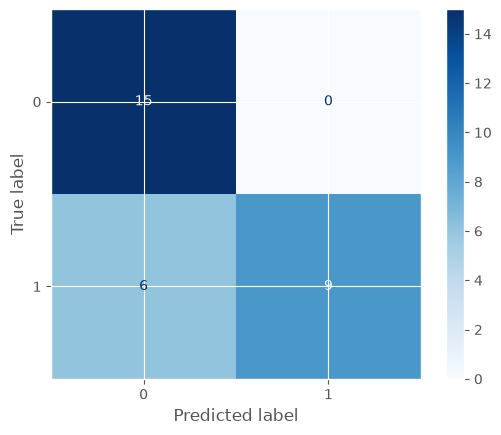

In [36]:
full_model = LogisticRegression(
            class_weight='balanced',
            max_iter=200,
            C=100
        )
n_tfidf = TfidfVectorizer(stop_words='english', max_features=5000, ngram_range=(1,2))
full_X = n_tfidf.fit_transform(X)
nx_test = n_tfidf.transform(emails)
ny_test = [
    1, 1, 1, 1, 1,
    1, 1, 1, 1, 1,
    1, 1, 1, 1, 1,

    0, 0, 0, 0, 0,
    0, 0, 0, 0, 0,
    0, 0, 0, 0, 0
]
full_model.fit(full_X, y)
npred = full_model.predict(nx_test)
ConfusionMatrixDisplay.from_estimator(
    full_model,
    nx_test,
    ny_test,
    cmap='Blues'
)
plt.show()

In [37]:
for p, email in zip(npred, emails):
    label = 'Spam' if p == 1 else 'Ham'
    print(f'{label} :{email}')

Spam :Congratulations! You have been selected for a $1,000,000 cash prize. Claim now!
Spam :URGENT: Your account has been compromised. Verify your information immediately.
Spam :You have won an exclusive prize! Click here to claim your reward.
Ham :Act now! Limited-time offer — get 90% off today only.
Ham :Your payment has failed. Update your billing information immediately.
Spam :Congratulations! You are our lucky winner. Send your details to receive your prize.
Spam :FINAL NOTICE: Your subscription will be cancelled unless you confirm your account.
Ham :Earn $5,000 per week working from home. No experience required!
Spam :You have been pre-approved for a special cash loan. Apply now.
Spam :Exclusive offer just for you! Buy now and receive a free gift.
Ham :Your package is waiting. Pay the delivery fee to schedule delivery.
Ham :Security Alert: Confirm your identity to prevent account suspension.
Spam :Claim your free gift card before this offer expires.
Spam :You have inherited money